In [ ]:
%matplotlib inline

# Solution 4 (optional) — Increase the IP beta functions

Try to increase both IP beta functions by a factor of five, from 0.09 m / 0.0008 m to 0.45 m / 0.0040 m. Keep a waist at the IP: $\alpha_x=\alpha_y=0$.

Match the two halves of the straight around `ipd`, keeping the nominal optics at the outer boundaries. Restore the nominal tunes and chromaticities with the arc circuits.

### Load the nominal lattice

In [1]:
import xtrack as xt

env = xt.load('fccee_z.json')
env.vars.load('optics_nominal.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)
tw0 = line.twiss4d(delta_chrom=1e-6)

### Inspect the experimental straight

In [2]:
ip = 'ipd'
start = 'end_ds_start_straight_ipd'
end = 'end_straight_start_ds_ipd'

tw0.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02473
ipd                             22665.1          0.09        0.0008  -6.72924e-09   2.38195e-08
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02472

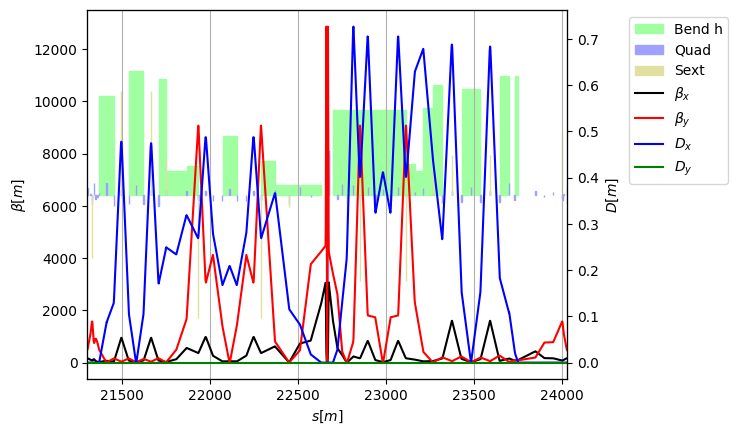

In [3]:
tw0.rows[start:end].plot()

### Quadrupoles for matching

Use the quadrupoles in the dispersion-free matching sections.

In [4]:
knobs_left = ['kqd16l', 'kqf17l', 'kqd18l', 'kqf19l', 'kqd20l',
              'kqd8m', 'kqf9m', 'kqd10m']
knobs_right = ['kqf17r', 'kqd18r', 'kqf19r', 'kqd20r',
               'kqd8mr', 'kqf9mr', 'kqd10mr']

### Fix the boundary optics

Use the nominal Twiss parameters at the two outer boundaries as initial conditions for open matching.

In [5]:
init_left = tw0.get_twiss_init(start)
init_right = tw0.get_twiss_init(end)

### Set the IP targets

Target five times the nominal beta functions and zero alpha in both planes. The supplied weights account for the different horizontal and vertical beta scales.

In [6]:
beta_factor = 5

targets_ip = [
    xt.Target('betx', at=ip, value=beta_factor * tw0['betx', ip], tol=1e-8, weight=10),
    xt.Target('bety', at=ip, value=beta_factor * tw0['bety', ip], tol=1e-10, weight=1000),
    xt.TargetSet(alfx=0, alfy=0, at=ip, tol=1e-7),
]

### Match the left half

Propagate from `start` to `ip` using `init_left` and vary `knobs_left`. Create the optimizer with `solve=False`, then run the matching with `.solve()`.

In [7]:
opt_left = line.match(
    solve=False,
    method='4d',
    start=start, end=ip, init=init_left,
    vary=xt.VaryList(knobs_left, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

In [8]:
opt_left.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx   False         -0.36          0.09          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety   False       -0.0032        0.0008         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -2.12212e-09  -2.12212e-09             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   2.38083e-08   2.38083e-08             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


In [9]:
opt_left.solve()

                                             
Optimize - start penalty: 4.817                         

Optimize - end penalty:  1.38988e-08                            


In [10]:
opt_left.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx    True   6.49324e-10          0.45          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True    5.5419e-13         0.004         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -1.22582e-09  -1.22582e-09             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -6.65152e-11  -6.65152e-11             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


### Match the right half

Use the range from `ip` to `end`, with `init_right` specified at `end`. Set `init_at=end` to propagate backwards from the downstream boundary.

In [11]:
opt_right = line.match(
    solve=False,
    method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=80,
)

In [12]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val    target_val description                                 
0  ON    ipd_betx   False         -0.36          0.09          0.45 ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety   False       -0.0032        0.0008         0.004 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -9.39167e-09  -9.39167e-09             0 ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True    2.3815e-08    2.3815e-08             0 ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


In [13]:
opt_right.solve()

                                             
Optimize - start penalty: 4.817                         

Optimize - end penalty:  2.66768e-10                            


### Limit the horizontal beta peak

After matching the IP, add an `xt.LessThan(2000)` target on the maximum horizontal beta in the right half. Clone the optimizer to keep the same IP targets, quadrupoles and boundary optics, then solve again.

In [14]:
opt_right = opt_right.clone(add_targets=[
    xt.Target(lambda tw: tw.betx.max(), xt.LessThan(2000),
              tol=1e-3, weight=1e-3, tag='max_betx'),
])

In [15]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val target_val           description                                 
0  ON    ipd_betx    True  -9.72594e-12          0.45 0.45000002105004744  ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True  -4.35936e-15         0.004 0.004000000497804704 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -2.48365e-11  -2.48365e-11 0                    ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   1.14805e-13   1.14805e-13 0                    ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
4  ON    max_betx    True             0       1172.03 LessThan(2000)       callable, val=LessThan(2000), tol=0.001, ...


In [16]:
opt_right.solve()

                                             
Optimize - start penalty: 2.668e-10                         

Optimize - end penalty:  2.66768e-10                            


In [17]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val target_val           description                                 
0  ON    ipd_betx    True  -9.72594e-12          0.45 0.45000002105004744  ('betx', 'ipd'), val=0.45, tol=1e-08, we ...
1  ON    ipd_bety    True  -4.35936e-15         0.004 0.004000000497804704 ('bety', 'ipd'), val=0.004, tol=1e-10, w ...
2  ON    ipd_alfx    True  -2.48365e-11  -2.48365e-11 0                    ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   1.14805e-13   1.14805e-13 0                    ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
4  ON    max_betx    True             0       1172.03 LessThan(2000)       callable, val=LessThan(2000), tol=0.001, ...


### Inspect the matched straight

Propagate through the entire straight from the fixed left boundary. Compare the IP beta functions and the recovered right-boundary optics with the nominal table above.

In [18]:
tw_local = line.twiss4d(start=start, end=end, init=init_left)
tw_local.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02473
ipd                             22665.1          0.45         0.004  -1.22582e-09  -6.65152e-11
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02472

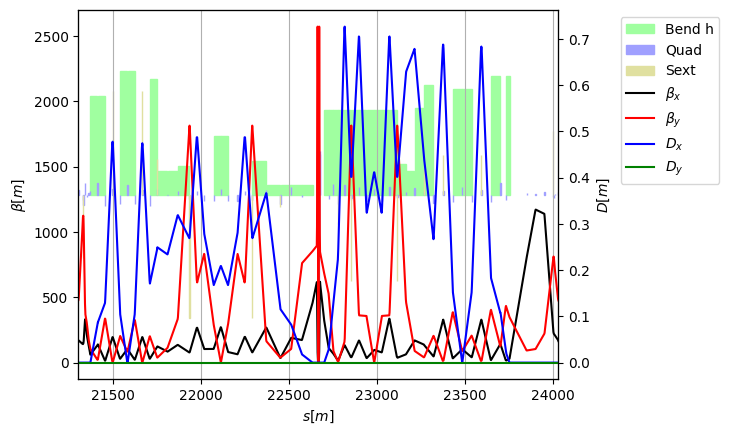

In [19]:
tw_local.plot()

### Restore the tunes

Use the arc quadrupole circuits `kqf2` and `kqd1` to recover the nominal tunes from `tw0`.

In [20]:
opt_tunes = line.match(
    solve=False,
    method='4d',
    vary=xt.VaryList(['kqf2', 'kqd1'], step=1e-8),
    targets=xt.TargetSet(qx=tw0.qx, qy=tw0.qy, tol=1e-8),
)

In [21]:
opt_tunes.target_status()

Target status:               
id state tag tol_met       residue   current_val    target_val description                           
0  ON    qx    False     -0.106256       166.054        166.16 'qx', val=166.16, tol=1e-08, weight=10
1  ON    qy    False     0.0277423       162.228         162.2 'qy', val=162.2, tol=1e-08, weight=10 


In [22]:
opt_tunes.solve()

                                             
Optimize - start penalty: 1.098                         

Optimize - end penalty:  1.24368e-08                            


### Restore the chromaticities

Use the arc sextupole families `ksf1` and `ksd1` to recover the nominal chromaticities. Keep `delta_chrom=1e-6`, as in the nominal calculation.

In [23]:
opt_chroma = line.match(
    solve=False,
    method='4d', delta_chrom=1e-6,
    vary=xt.VaryList(['ksf1', 'ksd1'], step=1e-5),
    targets=xt.TargetSet(dqx=tw0.dqx, dqy=tw0.dqy, tol=1e-3),
)

In [24]:
opt_chroma.target_status()

Target status:               
id state tag tol_met       residue   current_val    target_val description                            
0  ON    dqx   False      -11.2369      -4.75675       6.48014 'dqx', val=6.48014, tol=0.001, weight=1
1  ON    dqy   False      -25.2709      -17.4607       7.81025 'dqy', val=7.81025, tol=0.001, weight=1


In [25]:
opt_chroma.solve()

                                             
Optimize - start penalty: 27.66                         

Optimize - end penalty:  0.000284601                            


### Check the periodic ring

Recalculate the periodic optics and check all four IPs, tunes, and chromaticities. The arc quadrupole adjustment can slightly change the IP beta functions.

In [26]:
tw = line.twiss4d(delta_chrom=1e-6)
tw.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['betx bety alfx alfy']

TwissTable: 4 rows, 5 cols
name          betx          bety          alfx          alfy
ipa       0.449839    0.00399967  -6.25287e-05   1.57952e-05
ipd       0.449839    0.00399967  -6.25199e-05   1.57656e-05
ipg       0.449839    0.00399967  -6.25286e-05   1.57653e-05
ipj       0.449839    0.00399967  -6.25447e-05   1.57549e-05

In [27]:
print('Nominal tunes:', tw0.qx, tw0.qy)
print('Larger IP beta tunes:', tw.qx, tw.qy)

Nominal tunes: 166.15999999717738 162.20000000587538
Larger IP beta tunes: 166.15999999592518 162.20000000587413


In [28]:
print('Nominal chromaticities:', tw0.dqx, tw0.dqy)
print('Larger IP beta chromaticities:', tw.dqx, tw.dqy)
print('Maximum horizontal beta in right half [m]:', tw.rows[ip:end].betx.max())

Nominal chromaticities: 6.480135212960839 7.810249073901525
Larger IP beta chromaticities: 6.4798506121734345 7.8102490312689605
Maximum horizontal beta in right half [m]: 1171.6145711535623
